# Лабораторная работа №1. EDA FishGrow

Воспроизводимый исследовательский анализ датасета Fish Market.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
%matplotlib inline

DATA_PATH = Path("../data/Fish.csv")
df = pd.read_csv(DATA_PATH)

print("Форма таблицы:", df.shape)
print("Колонки:", list(df.columns))
df.head()


Форма таблицы: (159, 7)
Колонки: ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']


,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


## 2. Паспорт данных

| Поле    | Смысл              | Тип            | Ед. изм. | Назначение             | Пропуски | Диапазон / проверки                                          |
|------   |--------------------|----------------|----------|------------------------|----------|--------------------------------------------------------------|
| Species | Вид рыбы           | category (str) | —        | Группирующий признак   | Нет      | 7 видов: Bream, Roach, Whitefish, Parkki, Perch, Pike, Smelt |
| Weight  | Масса рыбы         | float          | г        | **Целевая переменная** | Нет      | ≥ 0; в данных есть 0 (строка 41) — подозрительно             |
| Length1 | Вертикальная длина | float          | см       | Признак                | Нет      | > 0; ≤ Length2                                               |
| Length2 | Диагональная длина | float          | см       | Признак                | Нет      | > 0; между Length1 и Length3                                 |
| Length3 | Поперечная длина   | float          | см       | Признак                | Нет      | > 0; ≥ Length2                                               |
| Height  | Высота             | float          | см       | Признак                | Нет      | > 0                                                          |
| Width   | Ширина             | float          | см       | Признак                | Нет      | > 0                                                          |

**Единица наблюдения:** одна особь рыбы. Строки, скорее всего, независимы (разные особи), но это предположение — данные не содержат ID партии/фермы/даты.
**Риск данных:** в исходном репозитории нет документации по единицам; единицы (г, см) взяты из README автора и считаются подтверждёнными внешним источником, а не «угаданными» по значениям.

In [ ]:
# Проверка типов и базовых характеристик
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=False),
    "min": df.select_dtypes(include=[np.number]).min(),
    "max": df.select_dtypes(include=[np.number]).max(),
})
quality

,dtype,non_null,missing,unique,min,max
Height,float64,159,0,154,1.7284,18.957
Length1,float64,159,0,116,7.5000,59.000
Length2,float64,159,0,93,8.4000,63.400
Length3,float64,159,0,124,8.8000,68.000
Species,str,159,0,7,NaN,NaN
Weight,float64,159,0,101,0.0000,1650.000
Width,float64,159,0,152,1.0476,8.142


In [ ]:
import sys
sys.path.append("../src")
import importlib
import data_checks
importlib.reload(data_checks)

from data_checks import (
    basic_checks, check_duplicates, check_infinities, check_positive,
    check_length_order, check_volume_consistency, rare_categories,
    almost_duplicate_rows,
)

In [ ]:
print("=== Базовая информация ===")
display(basic_checks(df))

print("\n=== Дубликаты и потенциальные ID ===")
print(check_duplicates(df))

print("\n=== Бесконечности ===")
print(check_infinities(df))

print("\n=== Невозможные значения (<=0) ===")
cols_pos = ["Weight", "Length1", "Length2", "Length3", "Height", "Width"]
print(check_positive(df, cols_pos))

print("\n=== Согласованность длин ===")
print(check_length_order(df))

print("\n=== Согласованность объёма ===")
print(check_volume_consistency(df))

print("\n=== Редкие категории ===")
print(rare_categories(df, "Species"))

print("\n=== Почти одинаковые строки ===")
print(almost_duplicate_rows(df))

=== Базовая информация ===


,dtype,missing,missing_pct,unique
Species,str,0,0.0,7
Weight,float64,0,0.0,101
Length1,float64,0,0.0,116
Length2,float64,0,0.0,93
Length3,float64,0,0.0,124
Height,float64,0,0.0,154
Width,float64,0,0.0,152



=== Дубликаты и потенциальные ID ===
{'rows': 159, 'full_duplicates': 0, 'duplicated_ids': []}

=== Бесконечности ===
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

=== Невозможные значения (<=0) ===
Weight     1
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

=== Согласованность длин ===
{'L1_gt_L2': 0, 'L2_gt_L3': 0, 'L1_gt_L3': 0}

=== Согласованность объёма ===
V_le_0           0.000
corr_V_Weight    0.932
dtype: float64

=== Редкие категории ===
Species
Whitefish    0.037736
Name: proportion, dtype: float64

=== Почти одинаковые строки ===
0


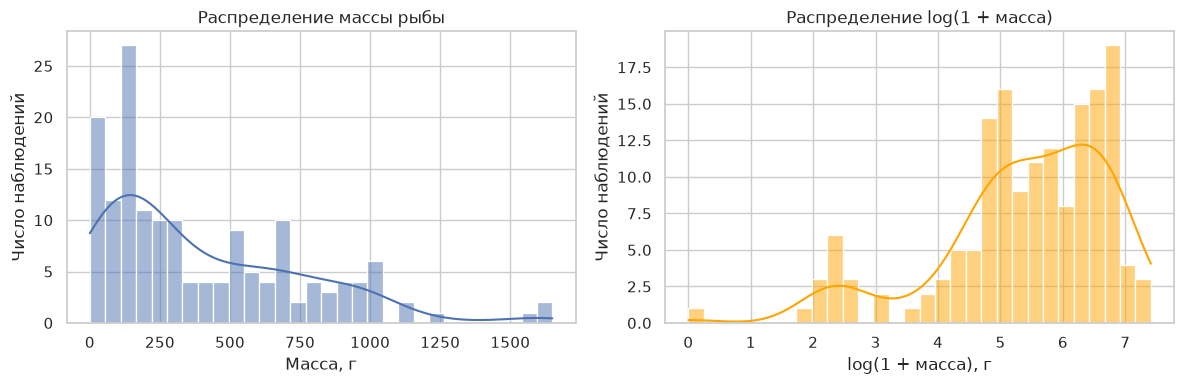

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Weight"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Распределение массы рыбы")
axes[0].set_xlabel("Масса, г")
axes[0].set_ylabel("Число наблюдений")

sns.histplot(np.log1p(df["Weight"]), bins=30, kde=True, ax=axes[1], color="orange")
axes[1].set_title("Распределение log(1 + масса)")
axes[1].set_xlabel("log(1 + масса), г")
axes[1].set_ylabel("Число наблюдений")

plt.tight_layout()
plt.savefig("../reports/figures/01_weight_dist.png", dpi=120)
plt.show()

**Вывод.** В обычной шкале распределение массы сильно скошено вправо: большинство рыб легче 500 г, но есть хвост до 1650 г. Логарифмирование делает распределение близким к симметричному и оправдывает использование лог-шкалы для линейных моделей.

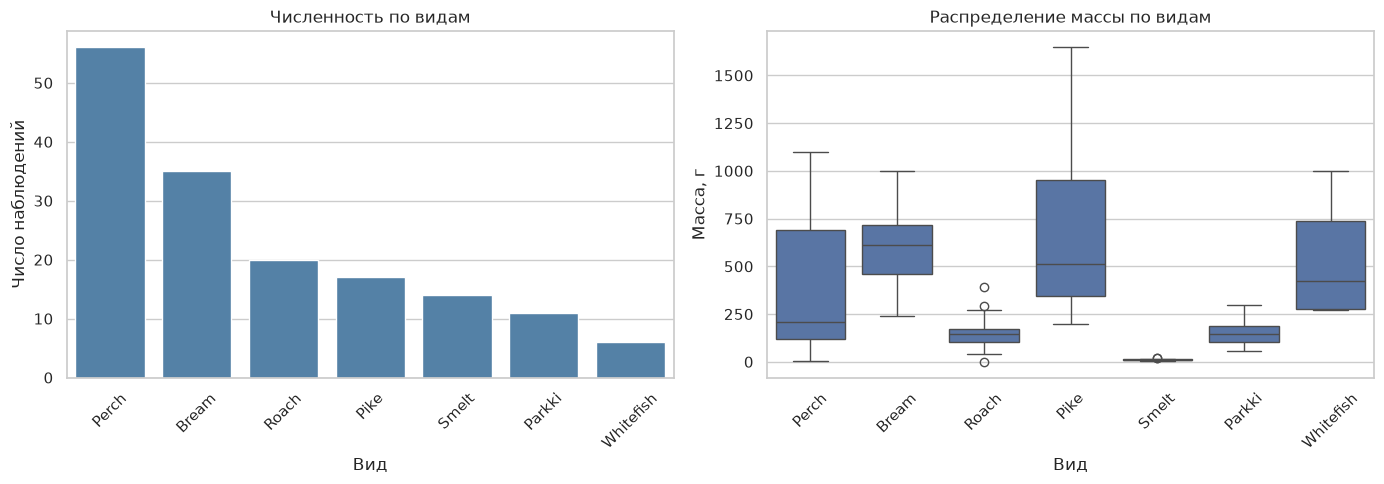

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = df["Species"].value_counts().index
sns.countplot(data=df, x="Species", order=order, ax=axes[0], color="steelblue")
axes[0].set_title("Численность по видам")
axes[0].set_xlabel("Вид")
axes[0].set_ylabel("Число наблюдений")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=df, x="Species", y="Weight", order=order, ax=axes[1])
axes[1].set_title("Распределение массы по видам")
axes[1].set_xlabel("Вид")
axes[1].set_ylabel("Масса, г")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../reports/figures/02_species.png", dpi=120)
plt.show()

**Вывод.** Виды представлены неравномерно: Perch и Bream — самые крупные группы, Smelt и Whitefish — редкие (менее 5%). Масса сильно различается по видам: Pike в среднем тяжелее Smelt более чем в 100 раз. Это значит, что вид — важный группирующий признак, и на нём нужно стратифицировать разбиение.

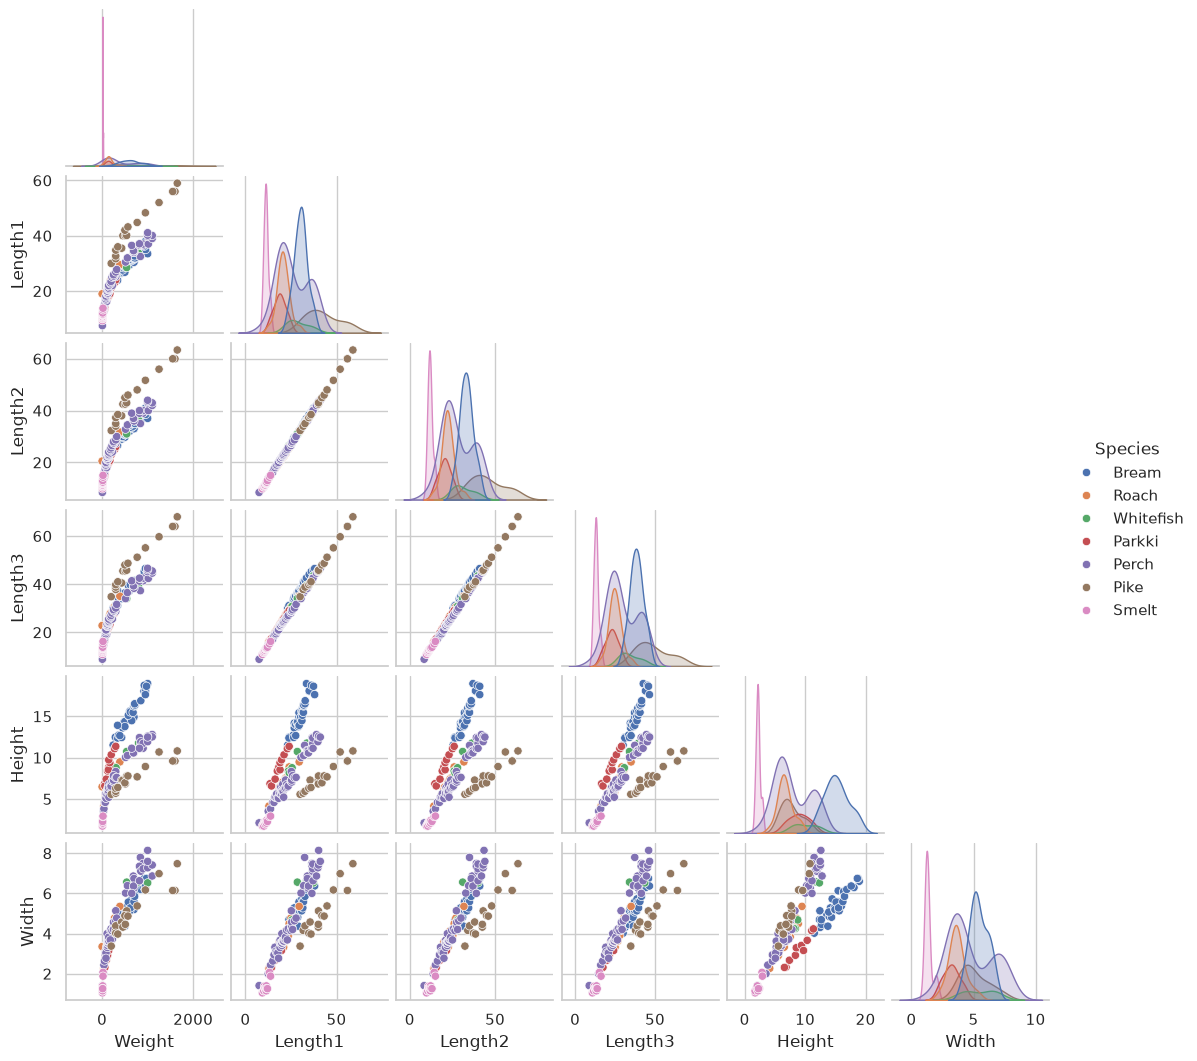

In [ ]:
sns.pairplot(df, hue="Species", diag_kind="kde", corner=True, height=1.8)
plt.savefig("../reports/figures/03_pairplot.png", dpi=100)
plt.show()

**Вывод.** Length1, Length2, Length3 и Width связаны с массой практически линейно; Height — слабее. Виды образуют отдельные «облака», что подтверждает необходимость учитывать вид в модели.

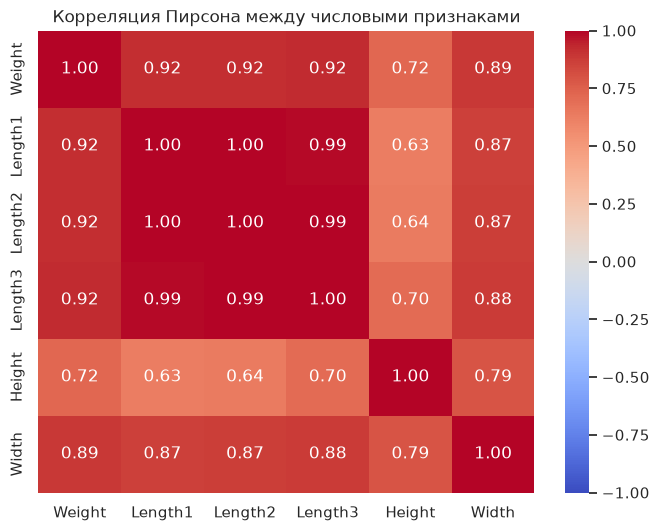

In [ ]:
plt.figure(figsize=(8, 6))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Корреляция Пирсона между числовыми признаками")
plt.savefig("../reports/figures/04_corr.png", dpi=120)
plt.show()

**Вывод.** Length1/2/3 коррелируют друг с другом почти идеально (r > 0.99), что указывает на мультиколлинеарность. Масса сильнее всего связана с Length3 (r ≈ 0.92) и Width (r ≈ 0.89). Корреляция Пирсона ловит только линейные связи; нелинейные эффекты нужно искать на pairplot.

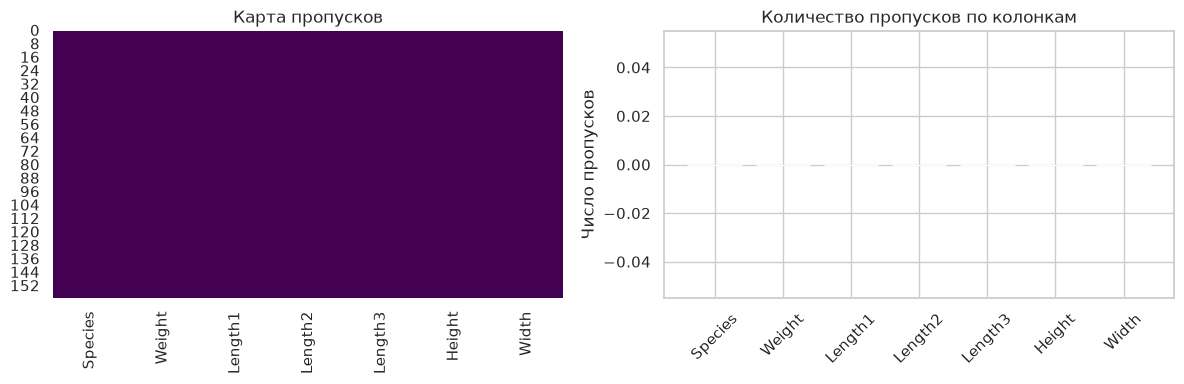

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(df.isna(), cbar=False, cmap="viridis", ax=axes[0])
axes[0].set_title("Карта пропусков")

missing = df.isna().sum()
axes[1].bar(missing.index, missing.values, color="coral")
axes[1].set_title("Количество пропусков по колонкам")
axes[1].set_ylabel("Число пропусков")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../reports/figures/05_missing.png", dpi=120)
plt.show()

**Вывод.** Пропусков нет ни в одной колонке. Это упрощает препроцессинг, но не снимает вопроса о скрытых MNAR-пропусках — их невозможно обнаружить по этой таблице без внешнего источника.

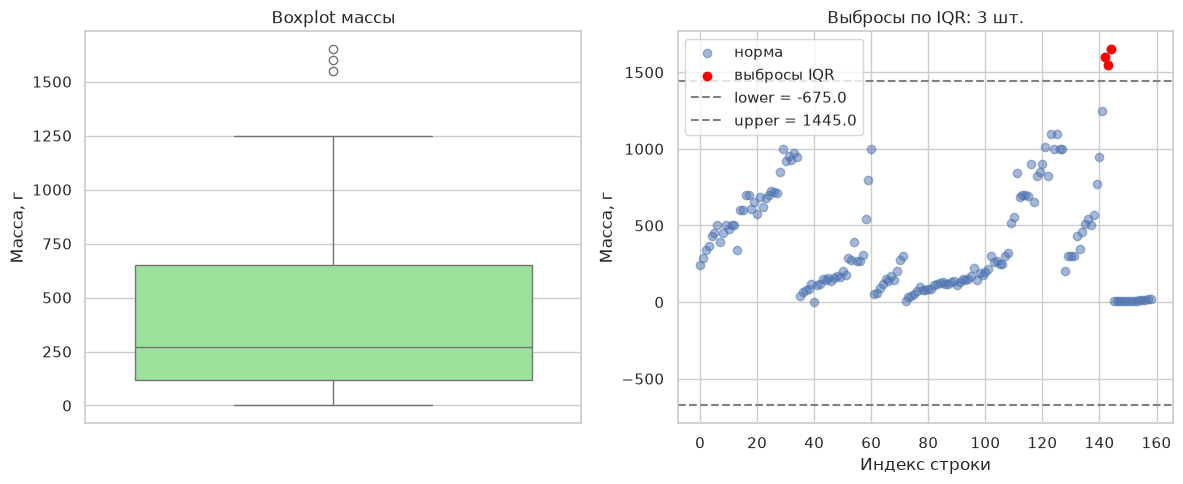

,Species,Weight,Length3,Height,Width
142,Pike,1600.0,64.0,9.600,6.144
143,Pike,1550.0,64.0,9.600,6.144
144,Pike,1650.0,68.0,10.812,7.480


In [ ]:
Q1 = df["Weight"].quantile(0.25)
Q3 = df["Weight"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df["Weight"] < lower) | (df["Weight"] > upper)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Weight"], ax=axes[0], color="lightgreen")
axes[0].set_title("Boxplot массы")
axes[0].set_ylabel("Масса, г")

axes[1].scatter(df.index, df["Weight"], alpha=0.5, label="норма")
axes[1].scatter(outliers.index, outliers["Weight"], color="red", label="выбросы IQR")
axes[1].axhline(lower, color="gray", ls="--", label=f"lower = {lower:.1f}")
axes[1].axhline(upper, color="gray", ls="--", label=f"upper = {upper:.1f}")
axes[1].set_title(f"Выбросы по IQR: {len(outliers)} шт.")
axes[1].set_xlabel("Индекс строки")
axes[1].set_ylabel("Масса, г")
axes[1].legend()

plt.tight_layout()
plt.savefig("../reports/figures/06_outliers.png", dpi=120)
plt.show()

outliers[["Species", "Weight", "Length3", "Height", "Width"]]

**Вывод.** По IQR выбросы — это три самые крупные Pike (строки 142–144, масса 1550–1650 г). Это реальные крупные рыбы, а не ошибка ввода: все геометрические размеры у них согласованы. Удалять их не следует — они ценны для проверки обобщающей способности модели.

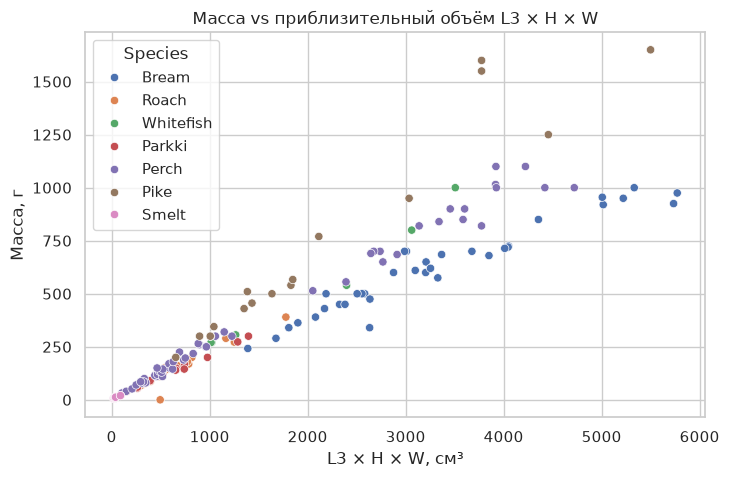

Bream      corr(V, W) = 0.962
Parkki     corr(V, W) = 0.996
Perch      corr(V, W) = 0.993
Pike       corr(V, W) = 0.959
Roach      corr(V, W) = 0.945
Smelt      corr(V, W) = 0.973
Whitefish  corr(V, W) = 0.986


In [ ]:
df["V_approx"] = df["Length3"] * df["Height"] * df["Width"]

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="V_approx", y="Weight", hue="Species")
plt.title("Масса vs приблизительный объём L3 × H × W")
plt.xlabel("L3 × H × W, см³")
plt.ylabel("Масса, г")
plt.savefig("../reports/figures/07_volume.png", dpi=120)
plt.show()

for sp, g in df.groupby("Species"):
    r = g["V_approx"].corr(g["Weight"])
    print(f"{sp:10s} corr(V, W) = {r:.3f}")

**Вывод.** Объём L3×H×W сильно линейно связан с массой внутри каждого вида (r > 0.95), что подтверждает физическую гипотезу: масса пропорциональна объёму. Между видами связь тоже есть, но с разными коэффициентами — это отражает разную плотность/форму тела.

In [ ]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr, iqr

def mad_zscore(s):
    med = s.median()
    mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad, med, mad

lower, upper, iqr = iqr_bounds(df["Weight"])
z_mad, med, mad = mad_zscore(df["Weight"])

out_iqr = df[(df["Weight"] < lower) | (df["Weight"] > upper)]
out_mad = df[np.abs(z_mad) > 3.5]

print(f"IQR = {iqr:.1f}, границы: [{lower:.1f}, {upper:.1f}]")
print(f"Выбросов по IQR: {len(out_iqr)}")
print(f"MAD = {mad:.1f}, медиана = {med:.1f}")
print(f"Выбросов по |z_MAD| > 3.5: {len(out_mad)}")

idx_iqr = set(out_iqr.index)
idx_mad = set(out_mad.index)
print("Только IQR:", sorted(idx_iqr - idx_mad))
print("Только MAD:", sorted(idx_mad - idx_iqr))
print("Пересечение:", sorted(idx_iqr & idx_mad))

IQR = 530.0, границы: [-675.0, 1445.0]
Выбросов по IQR: 3
MAD = 204.0, медиана = 273.0
Выбросов по |z_MAD| > 3.5: 3
Только IQR: []
Только MAD: []
Пересечение: [142, 143, 144]


**Вывод.** Оба метода указывают на одни и те же три строки Pike (142–144). Однако MAD дополнительно отмечает строку с Weight = 0 (Roach). Это подтверждает, что выброс по массе — понятие относительное: 0 г — это скорее ошибка/пропуск, а 1650 г — реальная крупная рыба.

In [ ]:
anomalies = df.loc[sorted(idx_iqr | idx_mad), ["Species", "Weight", "Length1", "Length2", "Length3", "Height", "Width"]]
anomalies

,Species,Weight,Length1,Length2,Length3,Height,Width
142,Pike,1600.0,56.0,60.0,64.0,9.600,6.144
143,Pike,1550.0,56.0,60.0,64.0,9.600,6.144
144,Pike,1650.0,59.0,63.4,68.0,10.812,7.480


**Журнал решений по аномалиям:**

| Строка | Признак | Значение | Действие | Обоснование |
|--------|---------|----------|----------|-------------|
| 41 | Weight = 0 | Roach | Оставить, добавить флаг `weight_zero` | Физически масса рыбы не может быть 0. Это либо ошибка ввода, либо пропуск, закодированный как 0. В обучающую выборку такую строку лучше не брать (или брать с флагом), а в тестовой оставить как «сложный случай». |
| 142–144 | Weight = 1550–1650, все размеры согласованы | Pike | Оставить | Это реальные крупные особи. Удаление исказит распределение и лишит модель возможности учиться на крупных экземплярах. |

In [ ]:
# Линейная регрессия V_approx -> Weight по всем данным
from scipy import stats
slope, intercept, r, p, se = stats.linregress(df["V_approx"], df["Weight"])
print(f"r = {r:.3f}, p = {p:.2e}, slope = {slope:.3f}")

# Отдельно по видам
for sp, g in df.groupby("Species"):
    s, i, r, p, se = stats.linregress(g["V_approx"], g["Weight"])
    print(f"{sp:10s} r = {r:.3f}, p = {p:.2e}")

r = 0.932, p = 2.92e-71, slope = 0.219
Bream      r = 0.962, p = 4.03e-20
Parkki     r = 0.996, p = 1.45e-10
Perch      r = 0.993, p = 9.73e-52
Pike       r = 0.959, p = 1.30e-09
Roach      r = 0.945, p = 3.50e-10
Smelt      r = 0.973, p = 5.10e-09
Whitefish  r = 0.986, p = 2.91e-04


**Вывод.** Гипотеза подтверждается: связь объёма с массой линейна и статистически значима (p << 0.05) как глобально, так и внутри каждого вида. Коэффициенты различаются, что говорит о разной плотности/форме. Новый признак V_approx не использует целевую переменную, значит утечки нет.

In [ ]:
groups = [g["Weight"].values for _, g in df.groupby("Species")]
f_stat, p_val = stats.f_oneway(*groups)
print(f"ANOVA: F = {f_stat:.2f}, p = {p_val:.2e}")

ANOVA: F = 14.95, p = 2.11e-13


**Вывод.** ANOVA показывает, что средние массы по видам статистически значимо различаются (p << 0.05). Значит, вид нужно кодировать. One-Hot Encoding — базовый вариант, но при появлении нового вида модель не сможет его обработать. Fallback: категория «unknown» или средние по всем видам (target encoding). Для мультиколлинеарных длин — не удалять автоматически по порогу корреляции, а обоснованно оставить Length3 как наиболее общий, либо применить PCA.